In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
df=pd.read_csv(r"C:\Users\Yadu krishna.M\Downloads\archive (2)\winequality-red.csv")
print("Data loaded successfully")
print(df.describe)
print("\ndataset info\n")
print(df.info)

print("\nchecking missing value\n")
print(df.isnull())

print("\nchecking missing value\n")
print(df.isnull().sum())

Data loaded successfully
<bound method NDFrame.describe of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47

In [11]:
#separate the input feature and target
X = df.drop("quality", axis=1)
Y = df["quality"]

normalizer=MinMaxScaler()
X_normalized = normalizer.fit_transform(X)

print("\nNormalized data (first 5 rows): ")
print(pd.DataFrame(
    X_normalized, columns=X.columns
).head().round(3))

standardizer = StandardScaler()
X_standardized = standardizer.fit_transform(X)

print("\nStandardised data (first 5 rows): ")
print(pd.DataFrame(
    X_standardized,columns=X.columns
).head().round(3))


Normalized data (first 5 rows): 
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.248             0.397         0.00           0.068      0.107   
1          0.283             0.521         0.00           0.116      0.144   
2          0.283             0.438         0.04           0.096      0.134   
3          0.584             0.110         0.56           0.068      0.105   
4          0.248             0.397         0.00           0.068      0.107   

   free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
0                0.141                 0.099    0.568  0.606      0.138   
1                0.338                 0.216    0.494  0.362      0.210   
2                0.197                 0.170    0.509  0.409      0.192   
3                0.225                 0.191    0.582  0.331      0.150   
4                0.141                 0.099    0.568  0.606      0.138   

   alcohol  
0    0.154  
1    0.215  
2    0.


PCA output (first 5 rows): 
     PC1    PC2
0 -1.620  0.451
1 -0.799  1.857
2 -0.748  0.882
3  2.358 -0.270
4 -1.620  0.451

Original number of feature: 11
Reduced number of features: 2

Varience retained by each component:
[0.2817 0.1751]
Total varience retained: 45.68 %


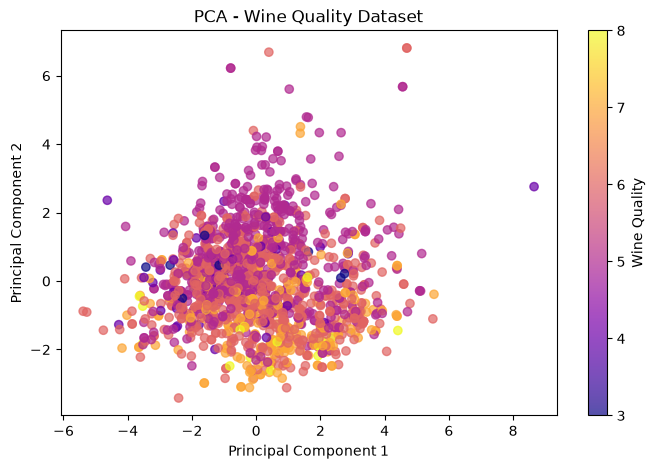

In [18]:
#Apllying PCA for Dimentional Reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)

print("\nPCA output (first 5 rows): ")
print(pd.DataFrame(
    X_pca, columns=["PC1", "PC2"]
).head().round(3))

print("\nOriginal number of feature:",X.shape[1])
print("Reduced number of features:",X_pca.shape[1])

print("\nVarience retained by each component:")
print(pca.explained_variance_ratio_.round(4))

print("Total varience retained:",
      round(sum(pca.explained_variance_ratio_) * 100,2),"%")

plt.figure(figsize=(8,5))
plt.scatter(X_pca[:,0], X_pca[:,1],
            c=Y, cmap="plasma", alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show()